### Probabilistic Generative Models -- Coursework 1
## Part 1

In [ ]:
import numpy as np
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt

# We set a global configuration for matplotlib to obtain well-readable plots
SMALL_SIZE = 9
MEDIUM_SIZE = 12
BIGGER_SIZE = 12

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)    # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# fixing random generator for reproducibility
rng = np.random.default_rng(0)

In [134]:
# some utils

def plot_mnist_vector(x, title=None):
    """
    Plot a 784-dimensional MNIST vector as a 28x28 image.

    """
    x = np.asarray(x)
    assert x.size == 784, "checking input dimension"

    img = x.reshape(28, 28)

    plt.figure(figsize=(2, 2))
    plt.imshow(img, cmap='gray', interpolation='nearest')
    plt.axis('off')

    if title is not None:
        plt.title(title)

    plt.show()
    
def plot_mnist_components(mu, titles=None):
    """
    Plot K MNIST vectors in a 2x5 grid.

    """
    K = mu.shape[0]
    assert K == 10, "expecting 10 components."

    fig, axes = plt.subplots(2, 5, figsize=(10, 4))

    for k, ax in enumerate(axes.flat):
        img = mu[k].reshape(28, 28)
        ax.imshow(img, cmap='gray', interpolation='nearest')
        ax.axis('off')
        if titles is not None:
            ax.set_title(titles[k], fontsize=10)

    plt.tight_layout()
    plt.show()
    
def logsumexp(a, axis=None, keepdims=False):
    a_max = np.max(a, axis=axis, keepdims=True)
    out = a_max + np.log(np.sum(np.exp(a - a_max), axis=axis, keepdims=True))
    if not keepdims:
        out = np.squeeze(out, axis=axis)
    return out

def bernoulli_mixture_nll(pi, mu, x, eps=1e-6):
    """
    Returns negative log-likelihood (scalar) for Bernoulli mixture.
    """
    mu = np.clip(mu, eps, 1 - eps)
    pi = np.clip(pi, eps, 1.0)

    log_mu = np.log(mu)               # (K,D)
    log_1m = np.log(1 - mu)           # (K,D)
    log_pi = np.log(pi)               # (K,)

    # log p(x_n | z=k): (N,D) @ (D,K) -> (N,K)
    log_lik = x @ log_mu.T + (1 - x) @ log_1m.T

    # log p(x_n) = log sum_k pi_k p(x_n|k)
    log_px = logsumexp(log_lik + log_pi[None, :], axis=1)  # (N,)

    return -np.sum(log_px)

    
def inspect_mu_values(mu, cluster_idx=0):
    """
    Inspects the numerical values of a specific cluster prototype.
    """
    # Get the vector for this cluster and reshape to 28x28
    prototype = mu[cluster_idx].reshape(28, 28)
    
    print(f"--- Inspecting Cluster {cluster_idx} ---")
    print(f"Min Value: {prototype.min():.4f} (Certain Black)")
    print(f"Max Value: {prototype.max():.4f} (Certain White)")
    print(f"Mean Value: {prototype.mean():.4f}")

    # Visual Heatmap with Colorbar
    plt.figure(figsize=(4, 3))
    plt.imshow(prototype, cmap='gray', vmin=0, vmax=1)
    plt.colorbar(label='Pixel Probability (mu)')
    plt.title(f"Heatmap of Cluster {cluster_idx}\n(0=Black, 1=White, 0.5=Gray)")
    plt.axis('off')
    plt.show()

    # Print a 5x5 block of raw numbers from the center of the image
    # (Rows 12-17, Cols 12-17)
    center_slice = prototype[12:17, 12:17]
    
    print("Raw Probability Values (Center 5x5 crop):")
    print(np.round(center_slice, 2))

In [7]:
# Load MNIST
mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X_image = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

# Choose M digits
digits = [1, 8, 0]   # choose any 3 digits
mask = np.isin(y, digits)

X_image = X_image[mask]
y = y[mask]

# Binarise
X = (X_image > 0.5).astype(np.int8)

print(X.shape)      
print(np.unique(y))  



(21605, 784)
[0 1 8]


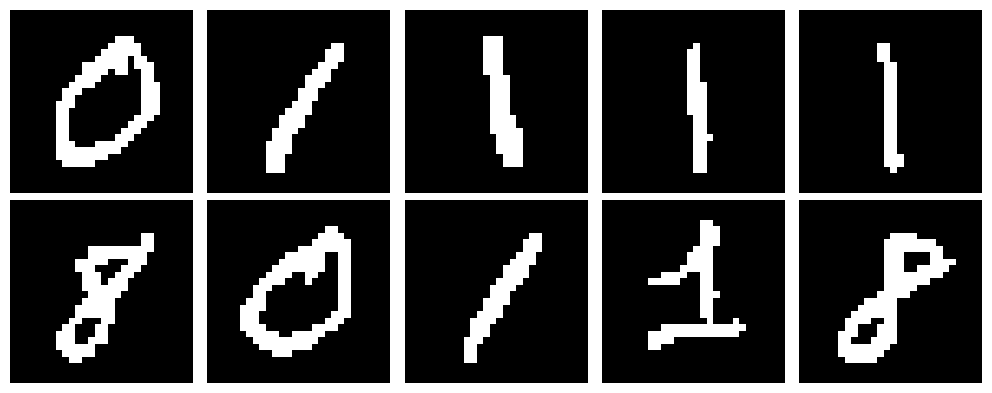

In [116]:
# plot 10 datapoints 
plot_mnist_components(X[:10,:])

In [117]:
# E step
def E_step(pi, mu, x, eps=1e-6):
    N, D = x.shape
    K = pi.shape[0]

    gamma_log = np.zeros((N, K), dtype=np.float64)

    for n in range(N):
        for k in range(K):
            gamma_log[n, k] = np.log(pi[k] + eps)
            for d in range(D):
                mu_kd = np.clip(mu[k, d], eps, 1 - eps)
                gamma_log[n, k] += x[n, d] * np.log(mu_kd) + (1 - x[n, d]) * np.log(1 - mu_kd)

    # normalise in a stable way
    gamma = np.empty_like(gamma_log)
    for n in range(N):
        m = np.max(gamma_log[n, :])
        row = np.exp(gamma_log[n, :] - m)
        gamma[n, :] = row / row.sum()

    return gamma

# M step
def M_step(gamma, x):
    N, D = x.shape
    N_eff = gamma.sum(axis=0)              # (K,)
    mu = (gamma.T @ x) / N_eff[:, None]    # (K, D)
    pi = N_eff / N
    return pi, mu
    

In [118]:
#training hyperparameters
N = 600
K = 3
EM_iterations = 10

#subset of data
x = X[:N,:]

# initialisation of parameters
D = x.shape[1] # dimension of the data
gamma = np.ones((N, K)) / K
pi = np.ones(K) * 1/K
mu = np.random.uniform(0.25, 0.75, size=(K, D))
eps = 1e-6



In [119]:
print(f'<<<Training the mixture model with EM for {EM_iterations} iterations>>>\n')
for i in range (EM_iterations):
    gamma = E_step(pi, mu, x)
    pi, mu =  M_step(gamma, x)
    loss = bernoulli_mixture_nll(pi, mu, x)
    print(f'Iteration {i} terminated with loss: {loss}')

<<<Training the mixture model with EM for 10 iterations>>>

Iteration 0 terminated with loss: 103583.9838145246
Iteration 1 terminated with loss: 94549.7012418876
Iteration 2 terminated with loss: 93354.815331304
Iteration 3 terminated with loss: 92888.97021089855
Iteration 4 terminated with loss: 92681.01028711189
Iteration 5 terminated with loss: 92357.8363290622
Iteration 6 terminated with loss: 92115.19318712268
Iteration 7 terminated with loss: 91905.54348642923
Iteration 8 terminated with loss: 91743.24591826052
Iteration 9 terminated with loss: 91622.3161758029


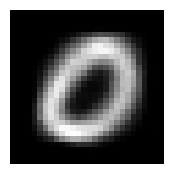

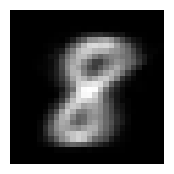

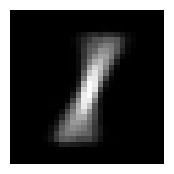

In [123]:
# plot the means of the Bernoulli mixtures. 
for i in range(K):
    plot_mnist_vector(mu[i,:])

--- Inspecting Cluster 1 ---
Min Value: 0.0000 (Certain Black)
Max Value: 1.0000 (Certain White)
Mean Value: 0.0678


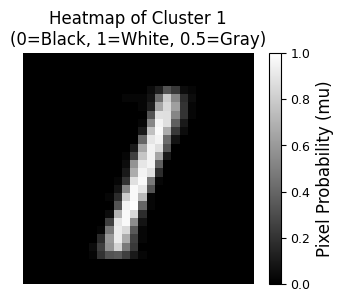

Raw Probability Values (Center 5x5 crop):
[[0.02 0.25 0.78 0.95 0.65]
 [0.05 0.57 0.9  0.95 0.37]
 [0.1  0.67 0.95 0.88 0.17]
 [0.2  0.88 0.98 0.47 0.02]
 [0.52 0.98 0.9  0.32 0.  ]]


In [139]:
inspect_mu_values(mu, cluster_idx=1)

In [128]:
def E_step_fast(pi, mu, x, eps=1e-6):
    """
    Vectorized E-step.
    Eliminates loops over N, K, and D.
    """
    N, D = x.shape
    K = pi.shape[0]

    # Pre-calculate Logarithms
    # Clip to avoid log(0)
    mu = np.clip(mu, eps, 1 - eps)
    pi = np.clip(pi, eps, 1.0)
    
    log_mu = np.log(mu)               # Shape: (K, D)
    log_1m_mu = np.log(1 - mu)        # Shape: (K, D)
    log_pi = np.log(pi)               # Shape: (K,)

    # Calculate Log-Likelihoods using Matrix Multiplication (@)
    # (N, D) @ (D, K) -> (N, K)
    log_bern = x @ log_mu.T + (1 - x) @ log_1m_mu.T
    
    # Add the priors (broadcasting)
    gamma_log = log_bern + log_pi[None, :]  # Shape: (N, K)

    # Normalize using Log-Sum-Exp trick (Vectorized)
    # Subtract max for stability
    m = np.max(gamma_log, axis=1, keepdims=True)
    gamma_shifted = gamma_log - m
    
    # Exponentiate and normalize
    exp_gamma = np.exp(gamma_shifted)
    gamma = exp_gamma / np.sum(exp_gamma, axis=1, keepdims=True)

    return gamma

In [ ]:
def init_bad_random(K, D):
    """
    Bad Init: Start with completely random uniform noise (0.25 to 0.75).
    The model knows nothing about the data shape.
    """
    pi = np.ones(K) / K
    mu = np.random.uniform(0.25, 0.75, size=(K, D))
    return pi, mu

def init_good_kmeans(X, K, n_iters=10):
    """
    Good Init: Run a quick K-Means on the binary data to find 
    rough cluster centers before starting EM.
    """
    N, D = X.shape
    # Pick random data points as starting centers
    indices = np.random.choice(N, K, replace=False)
    mu = X[indices].astype(float)
    
    # Quick K-Means loop (Hard Assignments)
    for i in range(n_iters):
        # Calculate distance (for binary, Squared Euclidean is fine as a proxy)
        # (N, 1, D) - (1, K, D)
        dists = np.sum((X[:, None, :] - mu[None, :, :])**2, axis=2)
        labels = np.argmin(dists, axis=1)
        
        # Update centers
        for k in range(K):
            if np.sum(labels == k) > 0:
                mu[k] = X[labels == k].mean(axis=0)
    
    # Clip to avoid log(0) and set equal weights
    mu = np.clip(mu, 0.25, 0.75) # Keep probabilities safe
    pi = np.ones(K) / K
    return pi, mu

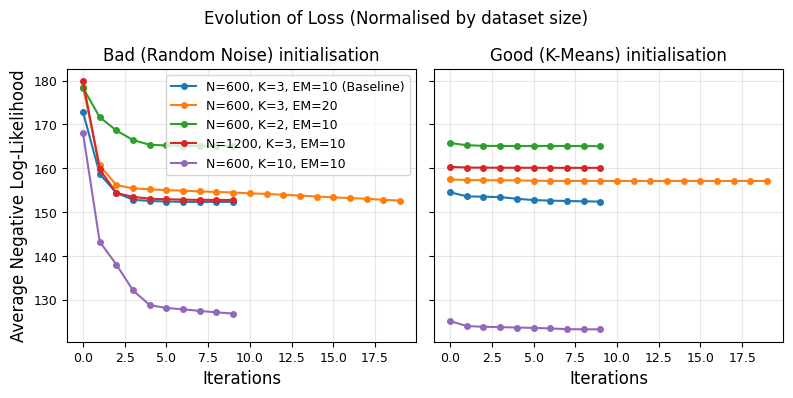

In [129]:
# Define the configurations
configs = [
    {"N": 600, "K": 3,  "EM": 10, "label": "N=600, K=3, EM=10 (Baseline)"},
    {"N": 600,  "K": 3,  "EM": 20, "label": "N=600, K=3, EM=20"},
    {"N": 600,  "K": 2,  "EM": 10, "label": "N=600, K=2, EM=10"},
    {"N": 1200, "K": 3,  "EM": 10, "label": "N=1200, K=3, EM=10"},
    {"N": 600,  "K": 10, "EM": 10, "label": "N=600, K=10, EM=10"}
]

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
strategies = ["Bad (Random Noise)", "Good (K-Means)"]

# Fix one seed so the data selection is consistent
np.random.seed(42)

for idx, strategy_name in enumerate(strategies):
    ax = axes[idx]
    
    for config in configs:
        N_cur = config["N"]
        K_cur = config["K"]
        iters = config["EM"]
        
        # Subset data
        x_train = X[:N_cur, :]
        D = x_train.shape[1]
        
        # INITIALIZATION
        if idx == 0:
            pi, mu = init_bad_random(K_cur, D)
        else:
            pi, mu = init_good_kmeans(x_train, K_cur)
        
        avg_losses = []
        
        # Training Loop
        for i in range(iters):
            gamma = E_step_fast(pi, mu, x_train)
            pi, mu = M_step(gamma, x_train)
            loss = bernoulli_mixture_nll(pi, mu, x_train)
            avg_losses.append(loss / N_cur)
            
        ax.plot(avg_losses, marker='o', linestyle='-', label=config["label"], markersize=4)

    ax.set_xlabel("Iterations")
    ax.set_title(f"{strategy_name} initialisation")
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.set_ylabel("Average Negative Log-Likelihood")
        ax.legend()

plt.suptitle("Evolution of Loss (Normalised by dataset size)")
plt.tight_layout()
plt.show()

In [146]:
def sample_bernoulli_mixture(pi, mu, n_samples=10):
    """
    Sample from a Bernoulli mixture model.
    pi: (K,) mixture weights
    mu: (K, D) Bernoulli parameters
    """
    K, D = mu.shape
    x_new = np.zeros((n_samples, D))
    
    # Pick a cluster k based on weights pi
    z_indices = np.random.choice(K, size=n_samples, p=pi)
    
    # Generate the pixels
    for i in range(n_samples):
        k = z_indices[i]
        
        # Sample each pixel d from Bernoulli
        # random.rand(D) generates uniform [0,1]. 
        # If rand < mu, result is 1. Else 0.
        x_new[i, :] = (np.random.rand(D) < mu[k]).astype(int)
        
    return x_new

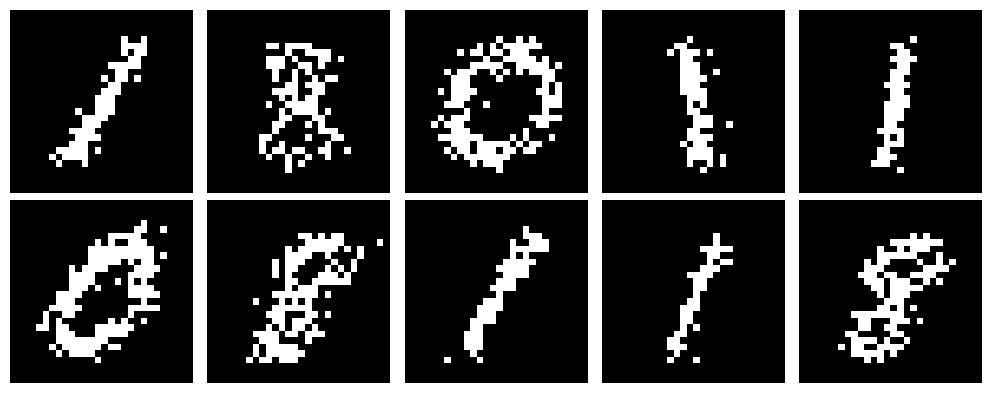

In [148]:
x_new = sample_bernoulli_mixture(pi, mu, n_samples=10)
plot_mnist_components(x_new)

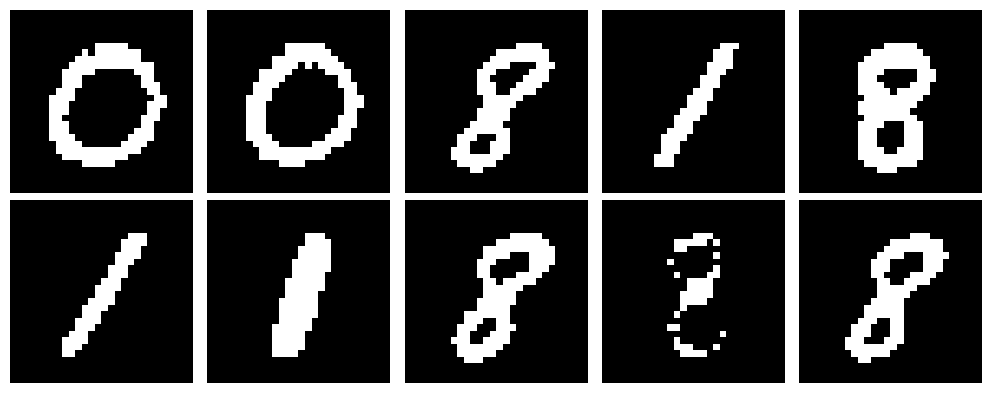

In [ ]:
def sample_bernoulli_mixture_temperature(pi, mu, alpha, n_samples=10):
    """
    Sample from a Bernoulli mixture model with temperature parameter
    """
    # Apply temperature Scaling to mu
    mu = (mu ** alpha) / (mu ** alpha + (1 - mu) ** alpha)
    
    # Apple ancestral sampling
    K, D = mu.shape
    x_new = np.zeros((n_samples, D))
    z_indices = np.random.choice(K, size=n_samples, p=pi)
    for i in range(n_samples):
        k = z_indices[i]
        x_new[i, :] = (np.random.rand(D) < mu[k]).astype(int)
        
    return x_new

# Visualize the effect of alpha
x_new = sample_bernoulli_mixture_temperature(pi, mu, alpha=10, n_samples=10)
plot_mnist_components(x_new)